<a href="https://colab.research.google.com/github/luis-fernando061/LFA/blob/main/Projeto_Final_Sentinela_Zap/Sentinela_Zap_Sistema_Especialista.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛡️ Sentinela Zap — Sistema Especialista para Filtragem de Mensagens Indesejadas no WhatsApp

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/luis-fernando061/LFA/blob/main/Projeto_Final_Sentinela_Zap/Sentinela_Zap_Sistema_Especialista.ipynb)

**Disciplina:** Linguagens Formais e Autômatos / Inteligência Artificial — UDF Centro Universitário<br>
**Professora:** Kadidja Valéria<br>
**Aluno:** Luis Fernando Vieira Borges — Turma N1<br>
**Repositório:** [github.com/luis-fernando061/LFA → Projeto_Final_Sentinela_Zap](https://github.com/luis-fernando061/LFA/tree/main/Projeto_Final_Sentinela_Zap)

**Tema escolhido:** Filtragem de mensagens indesejadas (canal: WhatsApp)

O projeto combina duas abordagens, como pede a Aula 13:

| Fase | O que faz | Quem constrói o conhecimento |
|---|---|---|
| **1. Modelo supervisionado** (Árvore de Decisão) | Lê atributos do texto e prevê a classe: `legitima`, `spam` ou `golpe` | Aprende com **exemplos rotulados** |
| **2. Sistema especialista** (regras SE…ENTÃO + motor de inferência) | Usa a previsão como **fato**, junta com fatos do contexto e decide a **ação**, explicando o porquê | **Regras escritas** a partir de orientações de prevenção a golpes |

> **Como executar no Google Colab:** clique no botão **Abrir no Colab** acima e depois em **Ambiente de execução → Executar tudo** (as células rodam de cima para baixo, em cerca de 30 segundos). Se o Colab avisar que o notebook não foi criado pelo Google, clique em **Executar mesmo assim**. O notebook é autocontido: o dataset está embutido e também é salvo como `mensagens_whatsapp.csv`.

## 1. A dor: por que este sistema é necessário

**O problema em números (Brasil):**

- **2.261.055 casos de estelionato** registrados em 2025, alta de cerca de **430% desde 2018** (20º Anuário Brasileiro de Segurança Pública, FBSP).
- **26,3 milhões de pessoas** (15,8% dos brasileiros com 16 anos ou mais) sofreram golpe ou perderam dinheiro por meios digitais em 2025 (FBSP).
- **32% dos usuários de internet** (≈ 45 milhões de pessoas) relataram tentativas de golpe com seus dados em 2025. Nesse grupo, **aplicativos de mensagem como WhatsApp e Telegram aparecem em 84%** dos relatos (Cetic.br/NIC.br).
- A Serasa aponta o WhatsApp em cerca de **40% das fraudes com engenharia social**.

> Os números vêm de pesquisas com metodologias diferentes (registros policiais, entrevistas, monitoramento) e **não devem ser somados ou comparados entre si**. Eles mostram a dimensão do problema.

**A dor na vida real (persona):**

> **Dona Marta, 63 anos**, recebe de um número desconhecido:
> *"Oi mãe, troquei de número. Salva esse. Preciso pagar um boleto urgente hoje, me faz um Pix que amanhã te devolvo."*
>
> Não há link nem erro de português. Um filtro de spam tradicional, que procura links e palavras de propaganda, deixa passar.
> Ela precisava de alguém que dissesse: **"Pare. Número novo + diz ser parente + pede dinheiro = padrão do golpe do falso parente. Ligue para o número antigo do seu filho antes de pagar."**

**Dor resumida:** o usuário **não consegue distinguir** golpe, propaganda indesejada e mensagem legítima, e **ninguém explica o porquê** de uma mensagem ser perigosa.

**Proposta de valor:** um **consultor especialista**. A pessoa cola a mensagem suspeita, responde no máximo duas perguntas e recebe **uma ação clara** (liberar, verificar, silenciar ou bloquear e denunciar), **com a justificativa** das regras usadas.

**Fontes:**
[Anuário FBSP 2026 (Brasil 61)](https://brasil61.com/n/anuario-de-seguranca-publica-brasil-registrou-mais-de-2-2-milhoes-de-casos-de-estelionato-em-2025-bras2616801) ·
[26,3 milhões de vítimas (Xataka)](https://www.xataka.com.br/informatica/a-nova-epidemia-brasileira-nao-esta-nas-ruas-os-golpes-digitais-ja-atingem-56-milhoes-pessoas-e-crime-fisico-ficou-para) ·
[Cetic.br: 84% via apps de mensagem (Viva)](https://viva.com.br/tecnologia/golpes-por-mensagem-e-ligacao-afetam-28-milhoes-de-usuarios-brasileiros.html) ·
[45 milhões com tentativas (Canaltech)](https://canaltech.com.br/seguranca/45-milhoes-de-brasileiros-ja-sofreram-tentativas-de-golpes-digitais-veja-os-mais-comuns/) ·
[Serasa: golpes de WhatsApp](https://www.serasa.com.br/premium/blog/golpes-de-whatsapp-saiba-e-previna-se/)

## 2. Domínio e escopo

**Domínio delimitado:** mensagens de texto recebidas no WhatsApp, em português.

**Entradas do sistema**
1. O **texto** da mensagem (colado pelo usuário).
2. **Fatos de contexto** que só o usuário sabe e que **não estão no texto**. O sistema só pergunta quando uma regra precisa deles:
   - `contato_salvo`: o número está salvo nos contatos?
   - `confirmou_por_ligacao`: a pessoa foi confirmada por uma ligação para o número antigo/conhecido?

**Classes previstas pelo modelo (rótulos)**

| Rótulo | Significado | Exemplo |
|---|---|---|
| `legitima` | Mensagem normal, desejada | "Pai, consegue me buscar às 22h?" |
| `spam` | Indesejada, mas **sem intenção de fraude** (propaganda, corrente) | "Repasse para 10 amigos…" |
| `golpe` | **Tentativa de fraude** (dinheiro, dados, código, conta) | "Me passa o código que chegou por SMS" |

**Saída:** uma **ação** (`LIBERAR`, `LIBERAR COM CAUTELA`, `VERIFICAR`, `ARQUIVAR`, `SILENCIAR E DENUNCIAR SPAM`, `NÃO PAGAR AINDA`, `BLOQUEAR E DENUNCIAR` ou `INCONCLUSIVO`), a **recomendação** e a **explicação**.

**Fora do escopo:** áudios, imagens, vídeos e ligações. O sistema também **não lê o WhatsApp automaticamente**, porque o aplicativo não permite isso a programas de terceiros. Ele funciona como um **consultor**.

## 3. Estudo inicial: respostas (Aula 13, seção 1)

**O que é aprendizado de máquina?**
É a área da IA em que o computador **aprende padrões a partir de dados**, em vez de receber cada regra programada à mão. O resultado é um *modelo* capaz de fazer previsões sobre casos novos.

**O que caracteriza o aprendizado supervisionado?**
O modelo é treinado com **exemplos cuja resposta correta já é conhecida** (rotulados). Ele aprende a relação entre entradas e respostas e depois prevê a resposta de casos que nunca viu.

**O que são atributos e rótulos?**
**Atributos** (*X*) são as características que descrevem cada caso. Aqui: quantidade de links, menções a dinheiro, pedido de código, palavras de urgência etc. **Rótulo** (*y*) é a resposta conhecida: `legitima`, `spam` ou `golpe`. O rótulo **nunca** entra em *X*, senão o modelo "veria a resposta".

**Como classificação difere de regressão?**
A **classificação** prevê uma **categoria** discreta (nosso caso: legítima, spam ou golpe). A **regressão** prevê um **valor numérico contínuo** (por exemplo, estimar o prejuízo em R$ de um golpe).

**Por que separar treino e teste?**
Para medir o desempenho em dados que o modelo **não viu**. Avaliar com os próprios dados de treino mede memorização (*overfitting*), não capacidade de generalizar.

## 4. Arquitetura

```
 Mensagem (texto)
      │
      ▼
 ┌─────────────────────────────────────┐
 │ Extração de atributos (LFA)          │  AFD reconhece links; expressões
 │  - AFD para URLs                     │  regulares detectam dinheiro,
 │  - Expressões regulares              │  código, troca de número, urgência...
 └─────────────────────────────────────┘
      │ atributos numéricos              │ fatos booleanos (tem_link, pede_dinheiro...)
      ▼                                  │
 ┌──────────────────────────┐            │
 │ FASE 1: Árvore de Decisão │            │
 │ (aprende com os dados)    │            │
 └──────────────────────────┘            │
      │ previsao = golpe/spam/legitima    │
      ▼                                  ▼
 ┌─────────────────────────────────────────────────────┐
 │ FASE 2: SISTEMA ESPECIALISTA                         │
 │  Memória de trabalho ◄── fatos do texto + previsão   │
 │  Base de conhecimento: regras R01…R18                │◄── pergunta ao usuário
 │  Motor de inferência: encadeamento para frente,      │    (contato salvo? confirmou?)
 │  prioridade, condição de parada, explicação          │
 └─────────────────────────────────────────────────────┘
      │
      ▼
 AÇÃO + recomendação + explicação ("como?" e "por quê?")
```

## 5. Bibliotecas

In [ ]:
import re
import unicodedata
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

pd.set_option("display.max_colwidth", 90)
print("Bibliotecas carregadas.")

Bibliotecas carregadas.


## 6. Dataset

| Item | Descrição |
|---|---|
| **Quantidade** | 150 mensagens: 50 `legitima`, 50 `spam`, 50 `golpe` (classes balanceadas) |
| **Origem** | ⚠️ **Dados SIMULADOS**, escritos pela equipe com base nos padrões de golpe descritos por Febraban, Serasa e pela Central de Ajuda do WhatsApp. Não são mensagens reais de pessoas. |
| **Atributos** | Extraídos automaticamente do texto (seção 7) |
| **Critério de rotulagem** | `golpe` = há intenção de obter **dinheiro, dados, senha/código ou a conta** da vítima por engano. `spam` = mensagem **não solicitada** (propaganda, corrente), sem fraude. `legitima` = conversa normal e esperada. |

Por serem simulados, os dados servem para **demonstrar o procedimento**, não para comprovar eficácia no mundo real (ver seção 18).

In [ ]:
# Dataset embutido (também salvo em CSV para entrega)
MENSAGENS = [
    ('Oi filho, já chegou em casa? Me avisa quando puder.', 'legitima'),
    ('Mãe, vou chegar mais tarde hoje, tenho reunião até as 19h.', 'legitima'),
    ('Pessoal, a reunião de amanhã foi remarcada para as 10h.', 'legitima'),
    ('Bom dia! Segue o link da aula de hoje: https://meet.google.com/abc-defg-hij', 'legitima'),
    ('Amor, compra pão quando voltar?', 'legitima'),
    ('Oi, aqui é a Dra. Ana do consultório. Confirmando sua consulta quinta às 14h. Responda SIM para confirmar.', 'legitima'),
    ('Galera, o churrasco de sábado tá confirmado! Cada um leva uma bebida.', 'legitima'),
    ('Olha esse vídeo que engraçado kkkkk https://www.youtube.com/watch?v=xyz123', 'legitima'),
    ('Já fiz o Pix da minha parte da pizza, confere aí.', 'legitima'),
    ('Professor, vou entregar o trabalho na sexta, tudo bem?', 'legitima'),
    ('Seu pedido #48213 saiu para entrega e chega hoje até as 18h.', 'legitima'),
    ('Pai, consegue me buscar na faculdade às 22h?', 'legitima'),
    ('Feliz aniversário!!! Muita saúde e paz pra você 🎉', 'legitima'),
    ('Tô no mercado, precisa de alguma coisa?', 'legitima'),
    ('Segue o comprovante do aluguel deste mês. Obrigado!', 'legitima'),
    ('Vó, a gente vai passar aí no domingo pra almoçar.', 'legitima'),
    ('O grupo de estudos vai ser na biblioteca às 15h, leva o caderno de LFA.', 'legitima'),
    ('Oi, tudo bem? Vi que você está vendendo a bicicleta, ainda está disponível?', 'legitima'),
    ('Chegou a encomenda que você pediu, deixei com o porteiro.', 'legitima'),
    ('Lembrete: vacina do Thor no veterinário amanhã às 9h.', 'legitima'),
    ('A conta de luz veio mais alta esse mês, vamos dividir certinho.', 'legitima'),
    ('Bom dia, equipe! O relatório está na pasta compartilhada: www.drive.google.com/pasta-relatorios', 'legitima'),
    ('Te devo 50 reais do cinema, faço o pix amanhã cedo.', 'legitima'),
    ('Mano, a prova de cálculo foi adiada para semana que vem.', 'legitima'),
    ('Oi! Sou a Carla, amiga da Júlia. Ela me passou seu número para combinar a carona.', 'legitima'),
    ('Obrigada pela ajuda ontem, você salvou meu dia!', 'legitima'),
    ('Meu voo atrasou, chego por volta da meia-noite.', 'legitima'),
    ('Oi tia, tudo bem? A mãe pediu pra avisar que o almoço é às 13h.', 'legitima'),
    ('Seu horário no salão foi confirmado para sábado às 10h.', 'legitima'),
    ('Filha, tô com saudade. Me liga quando puder.', 'legitima'),
    ('Oi pai, cheguei bem na casa da vó. Amanhã te ligo.', 'legitima'),
    ('Pessoal, quem vai no aniversário da Bia confirma aqui até sexta.', 'legitima'),
    ('Amiga, me manda a foto do caderno de ontem? Perdi a aula.', 'legitima'),
    ('Já paguei o boleto da internet, pode ficar tranquilo.', 'legitima'),
    ('Filho, a janta tá no forno. Esquenta 10 minutos.', 'legitima'),
    ('Bom dia, turma! Lembrando que a apresentação do projeto é na terça.', 'legitima'),
    ('Tia, obrigado pelo presente! Adorei a camisa.', 'legitima'),
    ('Mano, bora jogar bola hoje às 20h na quadra?', 'legitima'),
    ('Oi, aqui é o Pedro do estágio. Vou me atrasar uns 15 minutos para a reunião.', 'legitima'),
    ('Vou te mandar o endereço da festa mais tarde.', 'legitima'),
    ('Amor, esqueci a chave em casa, você ainda está aí?', 'legitima'),
    ('Segue a lista de compras: arroz, feijão, leite e café.', 'legitima'),
    ('O médico disse que está tudo bem com o exame. Fica tranquila!', 'legitima'),
    ('Você vai querer carona amanhã cedo? Saio às 7h.', 'legitima'),
    ('Parabéns pela aprovação!!! Muito orgulho de você!', 'legitima'),
    ('Gente, a aula de amanhã vai ser online. O link vai estar no ambiente virtual.', 'legitima'),
    ('Mãe, acabei de sair do trabalho, chego em 40 minutos.', 'legitima'),
    ('Pode me devolver o livro na segunda? Preciso para estudar.', 'legitima'),
    ('Oi vizinho, sua encomenda ficou aqui em casa, pode buscar quando quiser.', 'legitima'),
    ('Que saudade! Vamos marcar um café essa semana?', 'legitima'),
    ('PROMOÇÃO IMPERDÍVEL!!! Tênis com 70% de desconto só hoje. Confira: https://loja-ofertas.com/tenis', 'spam'),
    ('Repasse essa mensagem para 10 amigos ou terá 7 anos de azar!', 'spam'),
    ('Ganhe 20% de desconto na sua próxima pizza usando o cupom PIZZA20!', 'spam'),
    ('Atenção!!! Se você não compartilhar essa mensagem o WhatsApp vai começar a cobrar!!! Repasse!', 'spam'),
    ('Curso de inglês com 50% OFF! Matrículas abertas, chama no privado.', 'spam'),
    ('Bom dia! 🌻 Envie essa flor para 5 pessoas que você ama e receba uma bênção hoje.', 'spam'),
    ('Liquidação de verão! Roupas a partir de R$ 9,90. Visite nossa loja: www.modaverao.com.br', 'spam'),
    ('Oferta exclusiva: plano de celular com internet ilimitada por R$ 29,90/mês. Responda QUERO.', 'spam'),
    ('Você foi adicionado à lista de transmissão da Loja Tudo Barato. Novidades toda semana!', 'spam'),
    ('CORRENTE DA SORTE: compartilhe com 15 grupos e veja o que acontece em 3 dias!!!', 'spam'),
    ('Delivery de açaí com frete grátis hoje! Peça já pelo link https://acai-delivery.com', 'spam'),
    ('Conheça nosso novo cardápio! Promoção de marmitex por R$ 15. Entregamos na sua região.', 'spam'),
    ('Vendo produtos naturais, emagreça 10kg em 30 dias! Chama no privado para saber mais.', 'spam'),
    ('Black Friday antecipada!!! Eletrônicos com até 60% de desconto. Corre!', 'spam'),
    ('Pessoal, olha que absurdo, compartilhem para todos verem!!! Não deixem de repassar!', 'spam'),
    ('Seguro de carro com o melhor preço da região. Faça sua cotação grátis.', 'spam'),
    ('Academia Fit: matrícula grátis essa semana! Venha conhecer.', 'spam'),
    ('Mensagem de bom dia: Deus abençoe seu dia! Repasse para quem você gosta. 🙏', 'spam'),
    ('Últimas vagas para o workshop de marketing digital! Inscreva-se: https://workshopmkt.com.br', 'spam'),
    ('Lojas Sol: cupom de 15% válido até domingo. Use o código SOL15 no site.', 'spam'),
    ('Lindos vestidos de festa para aluguel. Agende sua prova!', 'spam'),
    ('ATENÇÃO MORADORES: dedetização com desconto para o condomínio, chame no privado!!!', 'spam'),
    ('Compre 2 e leve 3 em todos os perfumes! Promoção válida até sexta.', 'spam'),
    ('Venha para o rodízio de pizza por apenas R$ 39,90! Crianças até 5 anos não pagam.', 'spam'),
    ('Sorteio no Instagram! Siga a página, marque 3 amigos e concorra a um celular.', 'spam'),
    ('Consórcio sem juros! Realize o sonho do carro próprio. Fale com um consultor.', 'spam'),
    ('Novidade!!! Chegou a nova coleção de bolsas. Peça o catálogo pelo WhatsApp.', 'spam'),
    ('Envie essa corrente para 20 contatos e seu desejo vai se realizar até amanhã!', 'spam'),
    ('Promoção de troca de óleo: R$ 89 com filtro incluso. Agende já!', 'spam'),
    ('Aulas de violão com o primeiro mês grátis! Vagas limitadas.', 'spam'),
    ('Super oferta no açougue! Picanha com 30% de desconto neste fim de semana!', 'spam'),
    ('Aproveite: lavagem completa do carro por R$ 40. Agende pelo WhatsApp!', 'spam'),
    ('Confira nossas novidades em calçados! Peça o catálogo agora.', 'spam'),
    ('Passe essa mensagem adiante: amanhã é o dia mundial da gentileza! 💖', 'spam'),
    ('Clínica Sorriso: avaliação odontológica grátis. Marque seu horário!', 'spam'),
    ('Promoção relâmpago!!! Fones de ouvido a partir de R$ 19,90. Só hoje!', 'spam'),
    ('Hambúrguer artesanal em dobro às quartas! Confira o cardápio: www.burgerdobairro.com.br', 'spam'),
    ('Encaminhe para todos os seus grupos: a vacinação no posto do bairro vai até sábado!!!', 'spam'),
    ('Nova turma de pilates com desconto para os primeiros inscritos. Garanta sua vaga!', 'spam'),
    ('Você já conhece nossa loja? Roupas infantis com preço de fábrica. Chama no privado!', 'spam'),
    ('Bolos caseiros sob encomenda! Faça seu pedido com 2 dias de antecedência.', 'spam'),
    ('Oferta da semana no mercado: leve 3 pague 2 em todos os refrigerantes.', 'spam'),
    ('Mensagem do dia: sorria, Deus está no controle! Compartilhe com quem você ama 🙏', 'spam'),
    ('Pizzaria Bella: na compra de uma grande, ganhe um refrigerante! Peça já!', 'spam'),
    ('Inscrições abertas para o curso de informática básica! Últimas vagas!', 'spam'),
    ('Atenção!!! Repassem: o shopping vai fechar mais cedo no feriado!', 'spam'),
    ('Manicure em domicílio! Agende seu horário e ganhe 10% de desconto na primeira visita.', 'spam'),
    ('Chegaram os ovos de Páscoa artesanais! Encomende já o seu.', 'spam'),
    ('Imóveis à venda no centro com condições especiais! Fale com nosso corretor.', 'spam'),
    ('Liquidação total na loja de móveis! Tudo com até 50% OFF. Confira: https://moveis-liquida.com.br', 'spam'),
    ('Oi mãe, troquei de número. Salva esse aqui. Preciso de um favor urgente.', 'golpe'),
    ('Pai, esse é meu número novo. Consegue fazer um pix de R$ 850 pra mim agora? Amanhã te devolvo.', 'golpe'),
    ('Oi tia, meu celular quebrou e estou usando esse número. Preciso pagar um boleto hoje, pode me ajudar?', 'golpe'),
    ('Olá! Enviamos um código de verificação para seu número por engano. Pode me passar o código, por favor?', 'golpe'),
    ('Sua conta do banco foi bloqueada por movimentação suspeita. Regularize imediatamente: https://banco-seguranca.xyz/login', 'golpe'),
    ('Parabéns! Você ganhou um iPhone no sorteio. Clique e informe seus dados: https://premio-certo.site', 'golpe'),
    ('Vaga de emprego home office: ganhe R$ 300 por dia curtindo vídeos. Chame agora!', 'golpe'),
    ('Sua encomenda está retida. Pague a taxa de R$ 12,90 para liberar: https://rastreio-entrega.top', 'golpe'),
    ('Mãe, perdi meu chip, esse é meu número novo. Me empresta 500 no pix? É urgente.', 'golpe'),
    ('Aqui é do suporte do WhatsApp. Sua conta será desativada hoje. Me envie o código de 6 dígitos que chegou por SMS.', 'golpe'),
    ('Vendo videogame novo lacrado por R$ 1.200, só aceito pix adiantado. Últimas unidades!', 'golpe'),
    ('Seu CPF tem uma pendência na Receita. Regularize agora para evitar bloqueio: www.regulariza-cpf.info', 'golpe'),
    ('Oi, sou eu, mudei de número. Tô num aperto, faz uma transferência de 1.000 pra essa chave pix que te explico depois.', 'golpe'),
    ('Você foi selecionado para receber o auxílio de R$ 600. Cadastre-se: https://beneficio-gov.site', 'golpe'),
    ('Olá, aqui é da central do cartão. Detectamos uma compra de R$ 2.349. Se não reconhece, informe a senha do cartão para cancelar.', 'golpe'),
    ('Investimento garantido: dobre seu dinheiro em 24 horas! Deposite a partir de R$ 100.', 'golpe'),
    ('Filho, sou eu, o celular caiu na água e estou com esse número emprestado. Paga esse boleto pra mim hoje?', 'golpe'),
    ('Promoção do Dia das Mães: cesta grátis para os 100 primeiros! Responda com seu CPF e endereço: https://cestas-gratis.site', 'golpe'),
    ('Olá, sou recrutadora. Ganhe dinheiro avaliando produtos. Pague apenas R$ 50 de taxa de inscrição via pix.', 'golpe'),
    ('Sua conta de luz está atrasada e será cortada hoje. Pague via pix pelo link: https://energia-pagamento.xyz', 'golpe'),
    ('Oi amiga, tô sem acesso ao banco, pode me emprestar 200? Faz o pix nessa chave aqui que te devolvo amanhã.', 'golpe'),
    ('Confirme seu cadastro para não perder sua conta: digite o código que você recebeu.', 'golpe'),
    ('Ganhe um vale-compras de R$ 500! Basta clicar e preencher: https://vale-compras-gratis.top', 'golpe'),
    ('Seu FGTS tem valores a receber. Acesse imediatamente: https://saque-fgts-liberado.site', 'golpe'),
    ('Seu nome foi sorteado! Para receber o prêmio, pague a taxa de liberação de R$ 49,90.', 'golpe'),
    ('Vó, sou eu, troquei o número. Preciso de dinheiro pra consertar o carro, é urgente!', 'golpe'),
    ('Atenção: seu WhatsApp será clonado. Para proteger, envie o código de segurança que você recebeu.', 'golpe'),
    ('Oportunidade única: renda extra de R$ 5.000 por mês trabalhando 1 hora por dia! Clique: https://renda-facil.xyz', 'golpe'),
    ('Olá, sou do banco. Seu token expirou. Me informe o token gerado no app para reativar.', 'golpe'),
    ('Cliente, sua fatura vence hoje! Evite juros pagando pelo link: https://boleto-rapido.top', 'golpe'),
    ('Oi pai, meu celular foi roubado, tô usando o número de um amigo. Me manda 400 no pix pra eu pegar um uber?', 'golpe'),
    ('Seu pacote não pôde ser entregue. Atualize seu endereço e pague a taxa de reenvio: https://entrega-correio.top', 'golpe'),
    ('Olá, você foi selecionado para uma vaga de avaliador de hotéis. Ganhe R$ 150 por avaliação. Chame no privado!', 'golpe'),
    ('Detectamos um acesso suspeito na sua conta. Para não ser bloqueada, informe seu CPF e sua senha neste link: https://conta-protegida.site', 'golpe'),
    ('Mãe, sou eu, tô com celular novo. Pode pagar um boleto pra mim? É urgente.', 'golpe'),
    ('Promoção exclusiva para clientes: ganhe um celular novo pagando apenas o frete de R$ 29,90. Clique: https://brinde-celular.xyz', 'golpe'),
    ('Oi, é da escola do seu filho. Ele passou mal e precisamos de um pix de R$ 300 para o atendimento agora.', 'golpe'),
    ('Seu título de eleitor será cancelado. Regularize sua situação hoje: www.regulariza-titulo.info', 'golpe'),
    ('Ganhe dinheiro fácil! Invista R$ 200 e receba R$ 2.000 em uma semana. Garantido!', 'golpe'),
    ('Olá! Seu número foi sorteado no aniversário da loja. Para retirar o prêmio, envie o código que você recebeu por SMS.', 'golpe'),
    ('Aqui é da sua operadora. Seu chip será bloqueado hoje. Confirme seus dados respondendo com seu CPF.', 'golpe'),
    ('Vovó, sou eu! Mudei de número. Me empresta 250 pra pagar a faculdade? Devolvo semana que vem.', 'golpe'),
    ('Vendo celular seminovo por R$ 900, preciso vender hoje. Pagamento só por pix antecipado.', 'golpe'),
    ('Sua multa de trânsito vence hoje com 40% de desconto. Pague agora: https://multa-desconto.site', 'golpe'),
    ('Oi! Sou gerente do seu banco. Para cancelar uma compra indevida, preciso que você confirme o código que vai chegar.', 'golpe'),
    ('Trabalhe de casa curtindo posts e ganhe até R$ 500 por dia! Pague R$ 30 para liberar seu acesso.', 'golpe'),
    ('Seu benefício do INSS foi suspenso. Atualize seu cadastro imediatamente: https://inss-atualiza.top', 'golpe'),
    ('Filha, perdi meu celular. Esse é meu novo número. Consegue transferir 600 pra essa conta? É urgente!', 'golpe'),
    ('Parabéns, você ganhou um vale de R$ 1.000 do supermercado! Cadastre-se para resgatar: https://vale-mercado.site', 'golpe'),
    ('Olá, aqui é do suporte técnico. Sua conta será encerrada. Digite o código de verificação para manter seu acesso.', 'golpe'),
]

dados = pd.DataFrame(MENSAGENS, columns=["mensagem", "rotulo"])
dados.insert(0, "id", range(1, len(dados) + 1))
dados.to_csv("mensagens_whatsapp.csv", index=False)

print(f"Total de mensagens: {len(dados)}")
print(dados["rotulo"].value_counts().to_string())
dados.sample(6, random_state=1)

Total de mensagens: 150
rotulo
legitima    50
spam        50
golpe       50


,id,mensagem,rotulo
14,15,Segue o comprovante do aluguel deste mês. Obrigado!,legitima
98,99,Imóveis à venda no centro com condições especiais! Fale com nosso corretor.,spam
75,76,Consórcio sem juros! Realize o sonho do carro próprio. Fale com um consultor.,spam
16,17,"O grupo de estudos vai ser na biblioteca às 15h, leva o caderno de LFA.",legitima
131,132,Seu pacote não pôde ser entregue. Atualize seu endereço e pague a taxa de reenvio: htt...,golpe
56,57,"Liquidação de verão! Roupas a partir de R$ 9,90. Visite nossa loja: www.modaverao.com.br",spam


## 7. Extração de atributos com Linguagens Formais (AFD + Expressões Regulares)

Aqui entra a disciplina de **Linguagens Formais e Autômatos**. Os atributos são extraídos por reconhecedores de **linguagens regulares**.

### 7.1 Autômato Finito Determinístico (AFD) que reconhece links

Cada palavra (*token*) da mensagem é lida pelo AFD. O token é um link se pertence à linguagem

$$L_{URL} = \{\texttt{http://},\ \texttt{https://},\ \texttt{www.}\} \cdot \Sigma^{+}$$

em que Σ é o conjunto de caracteres que não são espaço.

**Definição formal:** $M = (Q, \Sigma, \delta, q_0, F)$

- $Q = \{q_0, h_1, h_2, h_3, h_4, h_5, c_1, c_2, c_3, w_1, w_2, w_3, q_f, q_{morto}\}$
- $q_0$ = estado inicial; $F = \{q_f\}$
- Transições principais:
  - `http`: $q_0 \xrightarrow{h} h_1 \xrightarrow{t} h_2 \xrightarrow{t} h_3 \xrightarrow{p} h_4$
  - `s` opcional: $h_4 \xrightarrow{s} h_5$
  - `://`: $h_4 \xrightarrow{:} c_1$, $h_5 \xrightarrow{:} c_1$, $c_1 \xrightarrow{/} c_2 \xrightarrow{/} c_3$
  - `www.`: $q_0 \xrightarrow{w} w_1 \xrightarrow{w} w_2 \xrightarrow{w} w_3 \xrightarrow{.} c_3$
  - Resto do link: $c_3 \xrightarrow{\Sigma} q_f$ e $q_f \xrightarrow{\Sigma} q_f$
  - Qualquer outra transição leva a $q_{morto}$, que rejeita.

A expressão regular **equivalente** é `^(https?://|www\.)\S+$`. Na célula 7.3 verificamos que **AFD e ER aceitam exatamente os mesmos tokens**.

In [ ]:
class AFD:
    # Autômato Finito Determinístico genérico: M = (Q, Σ, δ, q0, F)
    def __init__(self, transicoes, inicial, finais, transicoes_classe=None):
        self.delta = transicoes                 # dict: (estado, símbolo) -> estado
        self.q0 = inicial
        self.F = set(finais)
        # dict: estado -> (teste da classe de símbolos, estado destino). Ex.: "qualquer não-espaço"
        self.delta_classe = transicoes_classe or {}

    def proximo(self, estado, simbolo):
        if (estado, simbolo) in self.delta:
            return self.delta[(estado, simbolo)]
        if estado in self.delta_classe:
            pertence, destino = self.delta_classe[estado]
            if pertence(simbolo):
                return destino
        return "q_morto"

    def aceita(self, palavra, mostrar=False):
        estado = self.q0
        caminho = [estado]
        for simbolo in palavra:
            estado = self.proximo(estado, simbolo)
            caminho.append(estado)
            if estado == "q_morto":
                break
        if mostrar:
            print(" -> ".join(caminho), "| ACEITA" if estado in self.F else "| REJEITA")
        return estado in self.F


nao_espaco = lambda c: not c.isspace()     # Σ = qualquer caractere que não seja espaço

delta_url = {
    ("q0", "h"): "h1", ("h1", "t"): "h2", ("h2", "t"): "h3", ("h3", "p"): "h4",
    ("h4", "s"): "h5", ("h4", ":"): "c1", ("h5", ":"): "c1",
    ("c1", "/"): "c2", ("c2", "/"): "c3",
    ("q0", "w"): "w1", ("w1", "w"): "w2", ("w2", "w"): "w3", ("w3", "."): "c3",
}
afd_url = AFD(delta_url, "q0", {"q_f"},
              transicoes_classe={"c3": (nao_espaco, "q_f"), "q_f": (nao_espaco, "q_f")})

# Demonstração do caminho percorrido no autômato
for token in ["https://banco-seguranca.xyz", "www.site.com", "http:/erro", "whatsapp"]:
    print(f"{token!r:32}", end=" ")
    afd_url.aceita(token.lower(), mostrar=True)

'https://banco-seguranca.xyz'    q0 -> h1 -> h2 -> h3 -> h4 -> h5 -> c1 -> c2 -> c3 -> q_f -> q_f -> q_f -> q_f -> q_f -> q_f -> q_f -> q_f -> q_f -> q_f -> q_f -> q_f -> q_f -> q_f -> q_f -> q_f -> q_f -> q_f -> q_f | ACEITA
'www.site.com'                   q0 -> w1 -> w2 -> w3 -> c3 -> q_f -> q_f -> q_f -> q_f -> q_f -> q_f -> q_f -> q_f | ACEITA
'http:/erro'                     q0 -> h1 -> h2 -> h3 -> h4 -> c1 -> c2 -> q_morto | REJEITA
'whatsapp'                       q0 -> w1 -> q_morto | REJEITA


### 7.2 Expressões regulares para os demais sinais

Cada padrão abaixo também descreve uma **linguagem regular**. O texto é antes normalizado: minúsculas e sem acentos.

| Atributo | O que detecta | Por que importa (conhecimento do domínio) |
|---|---|---|
| `qtd_links` | Links (pelo **AFD**) | Golpes levam a páginas falsas |
| `qtd_dinheiro` | **Menções** a pix, boleto, transferência, depósito, R$… | Dinheiro aparece em golpes, mas também em conversas normais ("já fiz o pix") |
| `pedido_dinheiro` | **Pedido ativo**: "me empresta", "faz um pix", "pague a taxa", "preciso de dinheiro"… | Quase todo golpe termina pedindo que **a vítima pague** |
| `pede_codigo` | "me passa o código", código de verificação, token, senha do banco | Pedir código = tentativa de **clonar a conta** |
| `troca_numero` | "troquei de número", "número novo", "celular quebrou"… | Abertura típica do **golpe do falso parente** |
| `qtd_urgencia` | urgente, hoje, agora, bloqueada, expira… | Pressão para a vítima não pensar |
| `qtd_promocional` | promoção, desconto, grátis, cupom, sorteio… | Típico de propaganda (spam) e de falsos prêmios |
| `qtd_corrente` | repasse, compartilhe, envie para N pessoas… | Típico de corrente (spam) |
| `qtd_dados_sensiveis` | CPF, seus dados, endereço, cadastro, regularize, pendência… | Golpes tentam **roubar dados pessoais** |
| `qtd_institucional` | "prezado cliente", "sua conta", "central", "suporte", FGTS, auxílio… | Golpes **fingem ser banco, governo ou empresa** |
| `qtd_chamada_acao` | clique, acesse, cadastre-se, confira, agende, chama no privado… | Propaganda e golpe pedem que você **faça algo** |
| `qtd_tom_pessoal` | oi, mãe, pai, amor, mano, galera, saudade… | Conversa entre conhecidos (atenção: o falso parente **imita** esse tom) |
| `pct_maiusculas` | % de letras maiúsculas | "GRITAR" é comum em propaganda |
| `qtd_exclamacoes` | Quantidade de "!" | Idem |

In [ ]:
def normalizar(texto):
    # minúsculas e sem acentos: 'Código' -> 'codigo'
    texto = unicodedata.normalize("NFKD", texto.lower())
    return "".join(c for c in texto if not unicodedata.combining(c))

ER = {
    "dinheiro": re.compile(
        r"\bpix\b|transfer\w*|deposit\w*|\bboleto\b|\bemprest(a|e|ar|imo)\b|"
        r"\bpag(a|ar|ue|ando|amento)\b|\bdinheiro\b|\breais\b|r\$\s?\d|\bchave\b"),
    "codigo": re.compile(
        r"codigo (de )?(verificacao|seguranca|confirmacao|acesso|de \d)|"
        r"(mand|pass|envi|inform|digit|confirm)\w* o codigo|\btoken\b|"
        r"senha do (banco|cartao|aplicativo|app)"),
    "troca_numero": re.compile(
        r"(troquei|mudei) (de |o |meu |o meu )?(numero|celular|chip)|"
        r"numero novo|novo numero|celular novo|novo celular|"
        r"celular (quebrou|caiu|foi roubado|estragou)|numero de um amigo|"
        r"perdi (o |meu |o meu )?(celular|chip)|numero emprestado"),
    "urgencia": re.compile(
        r"\b(urgente|urgencia|agora|hoje|imediatamente|rapido|corre|ultimas?|"
        r"expira\w*|bloquead\w*|bloqueio|desativad\w*|cortad\w*|atrasad\w*|aperto)\b"),
    "promocional": re.compile(
        r"\b(promocao|desconto|gratis|oferta|cupom|sorteio|sorteado|ganhe|ganhou|"
        r"premio|imperdivel|frete|off|liquidacao|novidades?|matricula)\b"),
    "corrente": re.compile(
        r"\b(repasse|repassar|compartilh\w*|encaminhe|corrente)\b|envie essa"),
    # Pedido ATIVO de dinheiro: verbo de pedido seguido (na mesma frase, até 40
    # caracteres) de um objeto monetário. "Já fiz o pix" NÃO é pedido.
    "pedido_dinheiro": re.compile(
        r"\b(empresta\w*|faz|faca|fazer|manda|mande|envia|envie|transfere|transferir|"
        r"deposita|deposite|paga|pague|pagar)\b[^.?!]{0,40}"
        r"(\bpix\b|dinheiro|transferencia|deposito|boleto|taxa|reais|r\$)|"
        r"\b(empresta\w*|transfer\w*)( me)? (de )?\d|"
        r"\b(preciso|precisamos) (de )?(um )?(pix|dinheiro|pagar|\d)"),
    "dados_sensiveis": re.compile(
        r"\b(cpf|seus dados|endereco|cadastr\w*|senha|login|regulariz\w*|pendencia)\b"),
    "institucional": re.compile(
        r"\b(cliente|clientes|prezado|sua conta|seu cpf|sua fatura|seu nome|voce foi|parabens|"
        r"central|suporte|receita|fgts|auxilio|beneficio|operadora|gerente)\b"),
    "chamada_acao": re.compile(
        r"\b(clique|clica|acesse|cadastre|confira|garanta|aproveite|agende|inscreva|"
        r"encomende|responda|resgatar|atualize)\b|chama no privado|chame no privado|"
        r"chame agora|peca ja|peca o"),
    "tom_pessoal": re.compile(
        r"\b(oi|mae|pai|filho|filha|vo|vovo|tia|tio|amor|amiga|amigo|mano|galera|"
        r"gente|turma|vizinho|saudade)\b"),
}
ER_URL = re.compile(r"^(https?://|www\.)\S+$")   # ER equivalente ao AFD

ATRIBUTOS = ["qtd_links", "qtd_dinheiro", "pedido_dinheiro", "pede_codigo", "troca_numero",
             "qtd_urgencia", "qtd_promocional", "qtd_corrente",
             "qtd_dados_sensiveis", "qtd_institucional", "qtd_chamada_acao", "qtd_tom_pessoal",
             "pct_maiusculas", "qtd_exclamacoes"]

def extrair_atributos(texto):
    t = normalizar(texto)
    letras = [c for c in texto if c.isalpha()]
    return {
        "qtd_links": sum(afd_url.aceita(tok) for tok in t.split()),   # <- AFD
        "qtd_dinheiro": len(ER["dinheiro"].findall(t)),
        "pedido_dinheiro": int(bool(ER["pedido_dinheiro"].search(t))),
        "pede_codigo": int(bool(ER["codigo"].search(t))),
        "troca_numero": int(bool(ER["troca_numero"].search(t))),
        "qtd_urgencia": len(ER["urgencia"].findall(t)),
        "qtd_promocional": len(ER["promocional"].findall(t)),
        "qtd_corrente": len(ER["corrente"].findall(t)),
        "qtd_dados_sensiveis": len(ER["dados_sensiveis"].findall(t)),
        "qtd_institucional": len(ER["institucional"].findall(t)),
        "qtd_chamada_acao": len(ER["chamada_acao"].findall(t)),
        "qtd_tom_pessoal": len(ER["tom_pessoal"].findall(t)),
        "pct_maiusculas": round(100 * sum(c.isupper() for c in letras) / max(len(letras), 1), 1),
        "qtd_exclamacoes": texto.count("!"),
    }

extrair_atributos("Oi mãe, troquei de número! Me faz um PIX urgente: https://x.site")

{'qtd_links': 1,
 'qtd_dinheiro': 1,
 'pedido_dinheiro': 1,
 'pede_codigo': 0,
 'troca_numero': 1,
 'qtd_urgencia': 1,
 'qtd_promocional': 0,
 'qtd_corrente': 0,
 'qtd_dados_sensiveis': 0,
 'qtd_institucional': 0,
 'qtd_chamada_acao': 0,
 'qtd_tom_pessoal': 2,
 'pct_maiusculas': 10.6,
 'qtd_exclamacoes': 1}

### 7.3 Verificação formal: o AFD e a expressão regular reconhecem a mesma linguagem?

In [ ]:
tokens = {tok for m in dados["mensagem"] for tok in normalizar(m).split()}
tokens |= {"http://", "https://", "www.", "http:/x", "htps://x", "wwww.x", "www.a", "https://a"}

divergencias = [t for t in tokens if afd_url.aceita(t) != bool(ER_URL.match(t))]
print(f"Tokens testados: {len(tokens)} | Divergências AFD x ER: {len(divergencias)}")
assert not divergencias, divergencias
print("OK: o AFD e a expressão regular são equivalentes nos tokens testados.")

Tokens testados: 908 | Divergências AFD x ER: 0
OK: o AFD e a expressão regular são equivalentes nos tokens testados.


In [ ]:
# Tabela de atributos (X) e rótulo (y)
tabela = pd.concat([dados, dados["mensagem"].apply(extrair_atributos).apply(pd.Series)], axis=1)
X = tabela[ATRIBUTOS]
y = tabela["rotulo"]
tabela.groupby("rotulo")[ATRIBUTOS].mean().round(2)

,qtd_links,qtd_dinheiro,pedido_dinheiro,pede_codigo,troca_numero,qtd_urgencia,qtd_promocional,qtd_corrente,qtd_dados_sensiveis,qtd_institucional,qtd_chamada_acao,qtd_tom_pessoal,pct_maiusculas,qtd_exclamacoes
rotulo,,,,,,,,,,,,,,
golpe,0.36,1.22,0.38,0.18,0.24,0.64,0.46,0.00,0.44,0.58,0.24,0.40,4.58,0.40
legitima,0.06,0.10,0.00,0.00,0.00,0.08,0.00,0.02,0.02,0.02,0.02,0.66,3.90,0.34
spam,0.12,0.16,0.00,0.00,0.00,0.16,0.72,0.26,0.00,0.02,0.42,0.02,6.43,1.54


## 8. Fase 1: treino e avaliação do modelo supervisionado

- **Algoritmo:** `DecisionTreeClassifier` (árvore de decisão), o mesmo da aula. É interpretável: dá para ler as condições que ele aprendeu.
- **Divisão:** 75% treino e 25% teste, estratificada (`stratify=y`) para manter a proporção das classes, com `random_state=42` para ser reproduzível.
- **Escolha dos hiperparâmetros** (profundidade máxima, critério de divisão e mínimo de exemplos por folha): feita com `GridSearchCV`, que testa combinações por **validação cruzada dentro do conjunto de treino**. O conjunto de **teste fica guardado** e só é usado uma vez, no final. Isso segue o alerta da Aula 13: *"não ajuste repetidamente o modelo para acertar o mesmo teste; reserve validação separada quando houver ajustes"*.
- Limitar a profundidade reduz o *overfitting* (decorar os exemplos) num dataset pequeno.

Treino: 112 | Teste: 38
Melhores hiperparâmetros (validação no treino): {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 1}
Acurácia média na validação: 81.4%

Acurácia no teste: 76.3%

              precision    recall  f1-score   support

       golpe       0.78      0.58      0.67        12
    legitima       0.85      0.85      0.85        13
        spam       0.69      0.85      0.76        13

    accuracy                           0.76        38
   macro avg       0.77      0.76      0.76        38
weighted avg       0.77      0.76      0.76        38

               prev:legitima  prev:spam  prev:golpe
real:legitima             11          1           1
real:spam                  1         11           1
real:golpe                 1          4           7


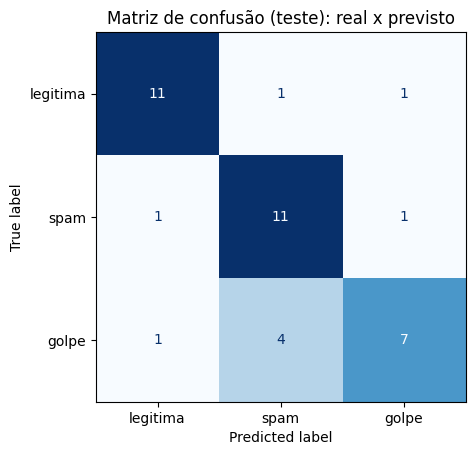

In [ ]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
print("Treino:", len(X_treino), "| Teste:", len(X_teste))

# 1) Validação: escolhe hiperparâmetros usando SOMENTE o treino
busca = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid={"max_depth": [3, 4, 5, 6],
                "criterion": ["gini", "entropy"],
                "min_samples_leaf": [1, 2, 3]},
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
busca.fit(X_treino, y_treino)
print("Melhores hiperparâmetros (validação no treino):", busca.best_params_)
print(f"Acurácia média na validação: {busca.best_score_:.1%}")

# 2) Modelo final, treinado com todo o conjunto de treino
modelo = busca.best_estimator_
previsoes = modelo.predict(X_teste)          # 3) Teste: casos que o modelo nunca viu

print(f"\nAcurácia no teste: {accuracy_score(y_teste, previsoes):.1%}\n")
print(classification_report(y_teste, previsoes, zero_division=0))

classes = ["legitima", "spam", "golpe"]
matriz = confusion_matrix(y_teste, previsoes, labels=classes)
print(pd.DataFrame(matriz, index=[f"real:{c}" for c in classes],
                   columns=[f"prev:{c}" for c in classes]))
ConfusionMatrixDisplay(matriz, display_labels=classes).plot(cmap="Blues", colorbar=False)
plt.title("Matriz de confusão (teste): real x previsto")
plt.show()

In [ ]:
# Validação cruzada (5 partes): resultado mais estável que um único teste pequeno
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
notas = cross_val_score(DecisionTreeClassifier(random_state=42, **busca.best_params_), X, y, cv=cv)
print("Acurácia em cada parte:", [f"{n:.0%}" for n in notas])
print(f"Média: {notas.mean():.1%}  (desvio padrão: {notas.std():.1%})")

Acurácia em cada parte: ['83%', '83%', '77%', '77%', '87%']
Média: 81.3%  (desvio padrão: 4.0%)


|--- qtd_exclamacoes <= 0.50
|   |--- qtd_urgencia <= 0.50
|   |   |--- qtd_institucional <= 0.50
|   |   |   |--- qtd_promocional <= 0.50
|   |   |   |   |--- pedido_dinheiro <= 0.50
|   |   |   |   |   |--- class: legitima
|   |   |   |   |--- pedido_dinheiro >  0.50
|   |   |   |   |   |--- class: golpe
|   |   |   |--- qtd_promocional >  0.50
|   |   |   |   |--- class: spam
|   |   |--- qtd_institucional >  0.50
|   |   |   |--- class: golpe
|   |--- qtd_urgencia >  0.50
|   |   |--- pct_maiusculas <= 3.55
|   |   |   |--- pct_maiusculas <= 2.95
|   |   |   |   |--- qtd_dinheiro <= 0.50
|   |   |   |   |   |--- class: golpe
|   |   |   |   |--- qtd_dinheiro >  0.50
|   |   |   |   |   |--- class: golpe
|   |   |   |--- pct_maiusculas >  2.95
|   |   |   |   |--- class: legitima
|   |   |--- pct_maiusculas >  3.55
|   |   |   |--- class: golpe
|--- qtd_exclamacoes >  0.50
|   |--- qtd_institucional <= 0.50
|   |   |--- pedido_dinheiro <= 0.50
|   |   |   |--- pede_codigo <= 0.50
| 

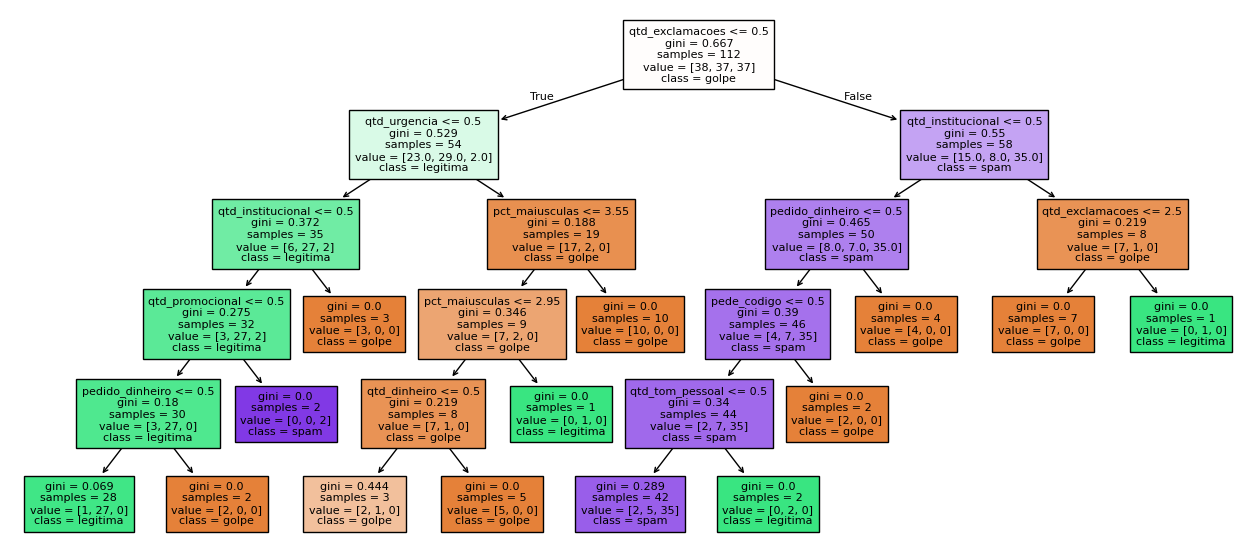

In [ ]:
# Condições aprendidas pela árvore (vêm dos DADOS, não do especialista)
print(export_text(modelo, feature_names=ATRIBUTOS))
plt.figure(figsize=(16, 7))
plot_tree(modelo, feature_names=ATRIBUTOS, class_names=list(modelo.classes_),
          filled=True, fontsize=8)
plt.show()

In [ ]:
# Erros do modelo no conjunto de teste (para discussão)
erros = tabela.loc[X_teste.index][y_teste != previsoes][["mensagem", "rotulo"]].copy()
erros["previsto"] = previsoes[(y_teste != previsoes).values]
erros if len(erros) else print("Nenhum erro no conjunto de teste.")

,mensagem,rotulo,previsto
3,Bom dia! Segue o link da aula de hoje: https://meet.google.com/abc-defg-hij,legitima,spam
138,Ganhe dinheiro fácil! Invista R$ 200 e receba R$ 2.000 em uma semana. Garantido!,golpe,spam
118,"Olá, sou recrutadora. Ganhe dinheiro avaliando produtos. Pague apenas R$ 50 de taxa de...",golpe,spam
110,"Vendo videogame novo lacrado por R$ 1.200, só aceito pix adiantado. Últimas unidades!",golpe,spam
88,Nova turma de pilates com desconto para os primeiros inscritos. Garanta sua vaga!,spam,legitima
1,"Mãe, vou chegar mais tarde hoje, tenho reunião até as 19h.",legitima,golpe
58,Você foi adicionado à lista de transmissão da Loja Tudo Barato. Novidades toda semana!,spam,golpe
122,Ganhe um vale-compras de R$ 500! Basta clicar e preencher: https://vale-compras-gratis...,golpe,spam
128,"Olá, sou do banco. Seu token expirou. Me informe o token gerado no app para reativar.",golpe,legitima


## 9. Fase 2: base de conhecimento (regras do especialista)

As regras **não** vêm dos dados. Elas formalizam orientações públicas de prevenção a golpes. Origem do conhecimento:
**[A]** Central de Ajuda do WhatsApp ("nunca compartilhe seu código de verificação"),
**[B]** Febraban e Serasa (golpe do falso parente: confirme por ligação antes de transferir),
**[C]** critério de projeto da equipe (como agir diante da previsão do modelo e do contexto).

| Regra | SE (condições) | ENTÃO (conclusão) | Prioridade | Origem |
|---|---|---|---|---|
| **R01** | troca_numero **E** pede_dinheiro | padrao_falso_parente | 100 | B |
| **R02** | pede_codigo | padrao_clonagem | 100 | A |
| **R03** | tem_link | sinal_risco = sim | 100 | C |
| **R04** | pede_dinheiro | sinal_risco = sim | 100 | C |
| **R05** | **não** tem_link **E não** pede_dinheiro | sinal_risco = não | 100 | C |
| **R06** | padrao_clonagem | **BLOQUEAR E DENUNCIAR** | 95 | A |
| **R07** | padrao_falso_parente **E** confirmou_por_ligacao = não | **BLOQUEAR E DENUNCIAR** | 90 | B |
| **R08** | padrao_falso_parente **E** confirmou_por_ligacao = sim | LIBERAR COM CAUTELA | 90 | B |
| **R09** | padrao_falso_parente **E** confirmou_por_ligacao = desconhecido | **NÃO PAGAR AINDA** | 90 | B |
| **R10** | previsao = golpe **E** contato_salvo = não **E** sinal_risco = sim | **BLOQUEAR E DENUNCIAR** | 50 | C |
| **R11** | previsao = golpe **E** contato_salvo = não **E** sinal_risco = não | VERIFICAR | 50 | C |
| **R12** | previsao = golpe **E** contato_salvo = sim | VERIFICAR (possível conta clonada) | 50 | B |
| **R13** | previsao = spam **E** contato_salvo = não | SILENCIAR E DENUNCIAR SPAM | 50 | C |
| **R14** | previsao = spam **E** contato_salvo = sim | ARQUIVAR | 50 | C |
| **R15** | previsao = legitima **E** contato_salvo = sim **E não** pede_dinheiro | LIBERAR | 50 | C |
| **R16** | previsao = legitima **E** contato_salvo = sim **E** pede_dinheiro | VERIFICAR (possível conta clonada) | 50 | B |
| **R17** | previsao = legitima **E** contato_salvo = não **E** sinal_risco = sim | VERIFICAR | 50 | C |
| **R18** | previsao = legitima **E** contato_salvo = não **E** sinal_risco = não | LIBERAR | 50 | C |

- `pede_dinheiro` significa **pedido ativo** ("me empresta", "faz um pix", "pague a taxa"). Só mencionar dinheiro, como em "já fiz o pix da pizza", não conta.
- **R01–R05** são regras **intermediárias**: geram fatos novos que outras regras usam (encadeamento).
- **R06–R09** reconhecem **padrões de golpe conhecidos** e têm prioridade **maior** que as regras baseadas no modelo (R10–R18). Assim o conhecimento do especialista prevalece mesmo se o modelo errar.
- A previsão do modelo entra como **fato** (`previsao`) nas regras **R10–R18**: é a **integração** pedida na Aula 13.
- **R10 × R11:** todo golpe precisa de um **vetor** (link, pedido de dinheiro ou de código). Se o modelo desconfia mas não há vetor, o sistema manda **verificar** em vez de bloquear. Isso evita bloquear por engano uma mensagem legítima de um número novo e ainda alerta na fase de "aquecimento" do golpe.
- **R16** cobre um ponto cego do modelo: um pedido de dinheiro escrito de forma natural, vindo de um contato salvo, parece "legítimo" pelo texto, mas pode vir de uma **conta clonada**.
- **R09** trata informação ausente: *não saber* se a pessoa foi confirmada é diferente de *saber que não foi* (Aula 12, slide 24).

In [ ]:
DESCONHECIDO = "desconhecido"

REGRAS = [
    # ---- Regras intermediárias (geram fatos novos) ----
    {"id": "R01", "prioridade": 100, "se": {"troca_numero": True, "pede_dinheiro": True},
     "entao": {"padrao_falso_parente": True},
     "texto": "SE diz que trocou de número E pede dinheiro ENTÃO padrão do golpe do falso parente"},
    {"id": "R02", "prioridade": 100, "se": {"pede_codigo": True},
     "entao": {"padrao_clonagem": True},
     "texto": "SE pede código/senha/token ENTÃO padrão de clonagem de conta"},
    {"id": "R03", "prioridade": 100, "se": {"tem_link": True},
     "entao": {"sinal_risco": True},
     "texto": "SE contém link ENTÃO há sinal de risco"},
    {"id": "R04", "prioridade": 100, "se": {"pede_dinheiro": True},
     "entao": {"sinal_risco": True},
     "texto": "SE pede dinheiro ENTÃO há sinal de risco"},
    {"id": "R05", "prioridade": 100, "se": {"tem_link": False, "pede_dinheiro": False},
     "entao": {"sinal_risco": False},
     "texto": "SE não tem link E não pede dinheiro ENTÃO não há sinal de risco"},

    # ---- Padrões de golpe conhecidos (prevalecem sobre o modelo) ----
    {"id": "R06", "prioridade": 95, "se": {"padrao_clonagem": True},
     "entao": {"acao": "BLOQUEAR E DENUNCIAR",
               "recomendacao": "NUNCA envie códigos, senhas ou tokens. Ninguém do WhatsApp ou do banco pede isso. "
                               "Bloqueie, denuncie e ative a confirmação em duas etapas."},
     "texto": "SE padrão de clonagem ENTÃO bloquear e denunciar"},
    {"id": "R07", "prioridade": 90, "se": {"padrao_falso_parente": True, "confirmou_por_ligacao": False},
     "entao": {"acao": "BLOQUEAR E DENUNCIAR",
               "recomendacao": "Não transfira. Ligue para o número ANTIGO da pessoa. Se não for ela, "
                               "bloqueie, denuncie e avise a família."},
     "texto": "SE falso parente E não confirmou por ligação ENTÃO bloquear e denunciar"},
    {"id": "R08", "prioridade": 90, "se": {"padrao_falso_parente": True, "confirmou_por_ligacao": True},
     "entao": {"acao": "LIBERAR COM CAUTELA",
               "recomendacao": "A identidade foi confirmada por ligação. Mesmo assim, confira o nome do "
                               "titular da chave Pix antes de pagar."},
     "texto": "SE falso parente E confirmou por ligação ENTÃO liberar com cautela"},
    {"id": "R09", "prioridade": 90, "se": {"padrao_falso_parente": True, "confirmou_por_ligacao": DESCONHECIDO},
     "entao": {"acao": "NÃO PAGAR AINDA",
               "recomendacao": "Informação insuficiente para liberar. Não faça nenhum pagamento até ligar "
                               "para o número antigo e confirmar quem está pedindo."},
     "texto": "SE falso parente E confirmação desconhecida ENTÃO suspender pagamento"},

    # ---- Regras que usam a PREVISÃO do modelo como fato ----
    {"id": "R10", "prioridade": 50, "se": {"previsao": "golpe", "contato_salvo": False, "sinal_risco": True},
     "entao": {"acao": "BLOQUEAR E DENUNCIAR",
               "recomendacao": "Não clique em links, não pague e não envie dados. Bloqueie e denuncie o número."},
     "texto": "SE modelo prevê golpe E número desconhecido E sinal de risco ENTÃO bloquear e denunciar"},
    {"id": "R11", "prioridade": 50, "se": {"previsao": "golpe", "contato_salvo": False, "sinal_risco": False},
     "entao": {"acao": "VERIFICAR",
               "recomendacao": "O texto lembra um golpe, mas ainda não há link nem pedido de dinheiro. Golpistas "
                               "costumam 'aquecer' a conversa antes de pedir. Não envie dados e confirme quem é."},
     "texto": "SE modelo prevê golpe E número desconhecido E sem sinal de risco ENTÃO verificar"},
    {"id": "R12", "prioridade": 50, "se": {"previsao": "golpe", "contato_salvo": True},
     "entao": {"acao": "VERIFICAR",
               "recomendacao": "A mensagem parece golpe, mas vem de um contato salvo: a conta dele pode ter "
                               "sido clonada. Ligue para a pessoa antes de qualquer ação."},
     "texto": "SE modelo prevê golpe E contato salvo ENTÃO verificar (possível conta clonada)"},
    {"id": "R13", "prioridade": 50, "se": {"previsao": "spam", "contato_salvo": False},
     "entao": {"acao": "SILENCIAR E DENUNCIAR SPAM",
               "recomendacao": "Mensagem não solicitada. Denuncie como spam e bloqueie, se quiser."},
     "texto": "SE modelo prevê spam E número desconhecido ENTÃO silenciar e denunciar spam"},
    {"id": "R14", "prioridade": 50, "se": {"previsao": "spam", "contato_salvo": True},
     "entao": {"acao": "ARQUIVAR",
               "recomendacao": "Propaganda ou corrente de um conhecido. Arquive a conversa. Não repasse correntes."},
     "texto": "SE modelo prevê spam E contato salvo ENTÃO arquivar"},
    {"id": "R15", "prioridade": 50, "se": {"previsao": "legitima", "contato_salvo": True, "pede_dinheiro": False},
     "entao": {"acao": "LIBERAR", "recomendacao": "Contato conhecido e nenhum pedido de dinheiro."},
     "texto": "SE modelo prevê legítima E contato salvo E não pede dinheiro ENTÃO liberar"},
    {"id": "R16", "prioridade": 50, "se": {"previsao": "legitima", "contato_salvo": True, "pede_dinheiro": True},
     "entao": {"acao": "VERIFICAR",
               "recomendacao": "O texto parece normal, mas é um PEDIDO DE DINHEIRO. Contas clonadas usam "
                               "contatos conhecidos: ligue para a pessoa e confirme antes de pagar."},
     "texto": "SE legítima E contato salvo E pede dinheiro ENTÃO verificar (possível conta clonada)"},
    {"id": "R17", "prioridade": 50, "se": {"previsao": "legitima", "contato_salvo": False, "sinal_risco": True},
     "entao": {"acao": "VERIFICAR",
               "recomendacao": "Parece legítima, mas vem de número desconhecido e envolve link ou pedido de "
                               "dinheiro. Confirme quem é antes de clicar ou pagar."},
     "texto": "SE legítima E número desconhecido E sinal de risco ENTÃO verificar"},
    {"id": "R18", "prioridade": 50, "se": {"previsao": "legitima", "contato_salvo": False, "sinal_risco": False},
     "entao": {"acao": "LIBERAR",
               "recomendacao": "Número desconhecido, mas sem link nem pedido de dinheiro."},
     "texto": "SE legítima E número desconhecido E sem sinal de risco ENTÃO liberar"},
]

# Fatos que o sistema pode PERGUNTAR ao usuário (não estão no texto)
PERGUNTAS = {
    "contato_salvo": "O número que enviou a mensagem está salvo nos seus contatos?",
    "confirmou_por_ligacao": "Você ligou para o número ANTIGO/conhecido da pessoa e ela confirmou o pedido?",
}
print(f"Base de conhecimento: {len(REGRAS)} regras | fatos perguntáveis: {list(PERGUNTAS)}")

Base de conhecimento: 18 regras | fatos perguntáveis: ['contato_salvo', 'confirmou_por_ligacao']


## 10. Motor de inferência

O motor segue o **ciclo de inferência** da Aula 12 com **encadeamento para frente**:

1. **Identificar** as regras cujas condições são satisfeitas pela memória de trabalho.
2. **Escolher** uma regra (resolução de conflitos): **maior prioridade** primeiro e, em empate, a ordem da base. Uma regra só é aplicável se produzir **informação nova** (refração).
3. **Executar** a conclusão, **atualizar** a memória e **repetir**.
4. **Se nenhuma regra é aplicável** mas uma regra só depende de um **fato perguntável ausente**, o sistema **pergunta ao usuário** e registra **por quê** está perguntando.

**Condições de parada:** o objetivo (`acao`) foi alcançado; nenhuma regra produz informação nova (→ `INCONCLUSIVO`, com encaminhamento humano); ou o limite de ciclos foi atingido.

**Explicação:** o **rastro** guarda cada regra disparada. A explicação **"Como?"** reconstrói a cadeia de regras e fatos que levou à conclusão.

In [ ]:
class MotorInferencia:
    def __init__(self, regras, perguntas, max_ciclos=50):
        # ordena por prioridade (estável: em empate vale a ordem da base)
        self.regras = sorted(regras, key=lambda r: -r["prioridade"])
        self.perguntas = perguntas
        self.max_ciclos = max_ciclos

    @staticmethod
    def _satisfeita(regra, memoria):
        return all(memoria.get(f, None) == v and f in memoria for f, v in regra["se"].items())

    @staticmethod
    def _traz_novidade(regra, memoria):
        return any(memoria.get(f, None) != v for f, v in regra["entao"].items())

    def _proxima_pergunta(self, memoria, disparadas):
        # Encontra a regra de maior prioridade que só depende de fatos perguntáveis ausentes
        for regra in self.regras:
            if regra["id"] in disparadas:
                continue
            faltando, possivel = [], True
            for fato, valor in regra["se"].items():
                if fato in memoria:
                    if memoria[fato] != valor:
                        possivel = False
                        break
                elif fato in self.perguntas:
                    faltando.append(fato)
                else:
                    possivel = False      # fato não perguntável ausente: regra não se aplica
                    break
            if possivel and faltando:
                return faltando[0], regra
        return None, None

    def executar(self, fatos_iniciais, responder):
        memoria = dict(fatos_iniciais)
        origem = {f: "entrada" for f in memoria}       # de onde veio cada fato
        disparadas, rastro, perguntas_feitas = [], [], []

        for ciclo in range(1, self.max_ciclos + 1):
            if "acao" in memoria:                          # parada: objetivo alcançado
                break
            aplicaveis = [r for r in self.regras if r["id"] not in disparadas
                          and self._satisfeita(r, memoria) and self._traz_novidade(r, memoria)]
            if aplicaveis:
                regra = aplicaveis[0]                      # resolução de conflito: prioridade
                for fato, valor in regra["entao"].items():
                    memoria[fato] = valor
                    origem[fato] = regra["id"]
                disparadas.append(regra["id"])
                rastro.append(f"Ciclo {ciclo}: {regra['id']} disparou -> {regra['texto']}")
                continue

            fato, regra = self._proxima_pergunta(memoria, disparadas)
            if fato is None:                               # parada: nada novo a produzir
                break
            por_que = f"a regra {regra['id']} precisa desse fato ({regra['texto']})"
            resposta = responder(fato, self.perguntas[fato], por_que)
            memoria[fato] = DESCONHECIDO if resposta is None else resposta
            origem[fato] = "usuário"
            perguntas_feitas.append({"fato": fato, "pergunta": self.perguntas[fato],
                                     "resposta": memoria[fato], "por_que": por_que})
            rastro.append(f"Ciclo {ciclo}: PERGUNTA '{fato}' (porque {por_que}) -> {memoria[fato]}")
        else:
            rastro.append("Limite de ciclos atingido: revisão necessária.")

        if "acao" not in memoria:
            memoria["acao"] = "INCONCLUSIVO"
            memoria["recomendacao"] = ("Nenhuma regra pôde concluir com as informações disponíveis. "
                                       "Não clique, não pague e peça ajuda a alguém de confiança.")
            origem["acao"] = "nenhuma regra"

        return {"memoria": memoria, "origem": origem, "disparadas": disparadas,
                "rastro": rastro, "perguntas": perguntas_feitas}

    def explicar_como(self, resultado, fato="acao", nivel=0):
        # Explicação "Como?": reconstrói a cadeia de regras que gerou o fato
        memoria, origem = resultado["memoria"], resultado["origem"]
        fonte = origem.get(fato, "?")
        linhas = [f"{'   ' * nivel}- {fato} = {memoria.get(fato)}  [origem: {fonte}]"]
        regra = next((r for r in self.regras if r["id"] == fonte), None)
        if regra:
            for condicao in regra["se"]:
                linhas += self.explicar_como(resultado, condicao, nivel + 1)
        return linhas

motor = MotorInferencia(REGRAS, PERGUNTAS)
print("Motor de inferência pronto.")

Motor de inferência pronto.


## 11. Integração: modelo + sistema especialista

A função `analisar_mensagem` junta tudo:

1. Valida a entrada.
2. Extrai os atributos (AFD + ER).
3. A **árvore de decisão prevê** a classe. A **previsão vira um fato** (`previsao`).
4. Os atributos booleanos viram fatos (`tem_link`, `pede_dinheiro`, `pede_codigo`, `troca_numero`).
5. O **motor de inferência** aplica as regras e, se precisar, pergunta ao usuário.
6. Devolve a ação, a recomendação, a explicação e avisos.

O parâmetro `respostas` simula as respostas do usuário, para os testes rodarem sem digitação. Uma resposta **ausente** vira `desconhecido`.

In [ ]:
def analisar_mensagem(texto, respostas=None, interativo=False):
    if not isinstance(texto, str) or not texto.strip():
        raise ValueError("A mensagem não pode estar vazia.")
    respostas = respostas or {}

    atributos = extrair_atributos(texto)
    entrada = pd.DataFrame([atributos])[ATRIBUTOS]
    previsao = modelo.predict(entrada)[0]
    # "Confiança" = proporção dos exemplos de treino daquela folha da árvore.
    # NÃO é uma probabilidade calibrada (Aula 12, slide 25).
    confianca = max(modelo.predict_proba(entrada)[0])

    fatos = {
        "previsao": previsao,
        "tem_link": atributos["qtd_links"] > 0,
        "pede_dinheiro": bool(atributos["pedido_dinheiro"]),   # pedido ativo, não mera menção
        "pede_codigo": bool(atributos["pede_codigo"]),
        "troca_numero": bool(atributos["troca_numero"]),
    }

    def responder(fato, pergunta, por_que):
        if interativo:
            print(f"\n❓ {pergunta}\n   (Por quê? Porque {por_que}.)")
            r = input("   Responda sim / nao / nao sei: ").strip().lower()
            r = normalizar(r)
            return True if r in ("sim", "s") else False if r in ("nao", "n") else None
        return respostas.get(fato)

    resultado = motor.executar(fatos, responder)
    fora = [c for c in ATRIBUTOS if not X_treino[c].min() <= atributos[c] <= X_treino[c].max()]
    resultado.update({
        "mensagem": texto, "atributos": atributos, "previsao": previsao,
        "confianca_folha": confianca,
        "aviso": (f"Atributos fora do intervalo visto no treino: {fora}. A previsão é menos confiável."
                  if fora else "Projeto didático: a recomendação não substitui o julgamento humano."),
    })
    return resultado


def mostrar(resultado):
    m = resultado["memoria"]
    print("=" * 90)
    print("MENSAGEM:", resultado["mensagem"])
    print(f"PREVISÃO DO MODELO: {resultado['previsao']} "
          f"(proporção na folha da árvore: {resultado['confianca_folha']:.0%})")
    fatos_texto = {k: m[k] for k in ("tem_link", "pede_dinheiro", "pede_codigo", "troca_numero")}
    print("FATOS DO TEXTO:", fatos_texto)
    for p in resultado["perguntas"]:
        print(f"PERGUNTOU: {p['pergunta']} -> {p['resposta']}\n   Por quê? Porque {p['por_que']}.")
    print("\nRASTRO DE INFERÊNCIA:")
    for linha in resultado["rastro"]:
        print("  ", linha)
    print(f"\n>>> AÇÃO: {m['acao']}")
    print(f">>> RECOMENDAÇÃO: {m['recomendacao']}")
    print("\nCOMO o sistema chegou a essa conclusão?")
    print("\n".join(motor.explicar_como(resultado)))
    print("\nAVISO:", resultado["aviso"])

## 12. Testes obrigatórios (Aula 12, slide 42)

| Teste | O que verifica |
|---|---|
| **Positivo** | Todas as condições de uma regra estão presentes, e ela dispara |
| **Negativo** | Uma condição necessária é falsa, e a regra **não** dispara |
| **Informação ausente** | Falta um fato para decidir, e o sistema não trata "não sei" como "não" |

Os `assert` fazem a célula **falhar** se o comportamento mudar. Funcionam como testes automatizados.

In [ ]:
msg_falso_parente = "Oi mãe, troquei de número. Me faz um pix de 700 reais agora? É urgente, depois te explico."

# --- TESTE 1: POSITIVO -> R01 e R07 devem disparar (falso parente, não confirmado)
t1 = analisar_mensagem(msg_falso_parente, respostas={"confirmou_por_ligacao": False})
mostrar(t1)
assert "R01" in t1["disparadas"] and "R07" in t1["disparadas"]
assert t1["memoria"]["acao"] == "BLOQUEAR E DENUNCIAR"
print("\n✅ TESTE POSITIVO OK")

MENSAGEM: Oi mãe, troquei de número. Me faz um pix de 700 reais agora? É urgente, depois te explico.
PREVISÃO DO MODELO: golpe (proporção na folha da árvore: 100%)
FATOS DO TEXTO: {'tem_link': False, 'pede_dinheiro': True, 'pede_codigo': False, 'troca_numero': True}
PERGUNTOU: Você ligou para o número ANTIGO/conhecido da pessoa e ela confirmou o pedido? -> False
   Por quê? Porque a regra R07 precisa desse fato (SE falso parente E não confirmou por ligação ENTÃO bloquear e denunciar).

RASTRO DE INFERÊNCIA:
   Ciclo 1: R01 disparou -> SE diz que trocou de número E pede dinheiro ENTÃO padrão do golpe do falso parente
   Ciclo 2: R04 disparou -> SE pede dinheiro ENTÃO há sinal de risco
   Ciclo 3: PERGUNTA 'confirmou_por_ligacao' (porque a regra R07 precisa desse fato (SE falso parente E não confirmou por ligação ENTÃO bloquear e denunciar)) -> False
   Ciclo 4: R07 disparou -> SE falso parente E não confirmou por ligação ENTÃO bloquear e denunciar

>>> AÇÃO: BLOQUEAR E DENUNCIAR
>>> REC

In [ ]:
# --- TESTE 2: NEGATIVO -> a mesma conversa SEM pedido de dinheiro.
# A condição 'pede_dinheiro' de R01 é falsa, então R01 NÃO pode disparar.
t2 = analisar_mensagem("Oi mãe, troquei de número, salva esse aqui. Beijos!",
                       respostas={"contato_salvo": False})
mostrar(t2)
assert "R01" not in t2["disparadas"]
assert t2["memoria"].get("padrao_falso_parente") is None
print("\n✅ TESTE NEGATIVO OK: sem pedido de dinheiro, o padrão de falso parente não é concluído.")

MENSAGEM: Oi mãe, troquei de número, salva esse aqui. Beijos!
PREVISÃO DO MODELO: legitima (proporção na folha da árvore: 100%)
FATOS DO TEXTO: {'tem_link': False, 'pede_dinheiro': False, 'pede_codigo': False, 'troca_numero': True}
PERGUNTOU: O número que enviou a mensagem está salvo nos seus contatos? -> False
   Por quê? Porque a regra R15 precisa desse fato (SE modelo prevê legítima E contato salvo E não pede dinheiro ENTÃO liberar).

RASTRO DE INFERÊNCIA:
   Ciclo 1: R05 disparou -> SE não tem link E não pede dinheiro ENTÃO não há sinal de risco
   Ciclo 2: PERGUNTA 'contato_salvo' (porque a regra R15 precisa desse fato (SE modelo prevê legítima E contato salvo E não pede dinheiro ENTÃO liberar)) -> False
   Ciclo 3: R18 disparou -> SE legítima E número desconhecido E sem sinal de risco ENTÃO liberar

>>> AÇÃO: LIBERAR
>>> RECOMENDAÇÃO: Número desconhecido, mas sem link nem pedido de dinheiro.

COMO o sistema chegou a essa conclusão?
- acao = LIBERAR  [origem: R18]
   - previsao = 

In [ ]:
# --- TESTE 3: INFORMAÇÃO AUSENTE -> o usuário NÃO SABE se a pessoa foi confirmada.
t3 = analisar_mensagem(msg_falso_parente, respostas={})     # nenhuma resposta disponível
mostrar(t3)
assert t3["memoria"]["confirmou_por_ligacao"] == DESCONHECIDO
assert t3["memoria"]["acao"] == "NÃO PAGAR AINDA"            # R09, e não R07
assert t3["memoria"]["acao"] != t1["memoria"]["acao"]
print("\n✅ TESTE DE INFORMAÇÃO AUSENTE OK: 'não sei' gerou uma recomendação diferente de 'não'.")

MENSAGEM: Oi mãe, troquei de número. Me faz um pix de 700 reais agora? É urgente, depois te explico.
PREVISÃO DO MODELO: golpe (proporção na folha da árvore: 100%)
FATOS DO TEXTO: {'tem_link': False, 'pede_dinheiro': True, 'pede_codigo': False, 'troca_numero': True}
PERGUNTOU: Você ligou para o número ANTIGO/conhecido da pessoa e ela confirmou o pedido? -> desconhecido
   Por quê? Porque a regra R07 precisa desse fato (SE falso parente E não confirmou por ligação ENTÃO bloquear e denunciar).

RASTRO DE INFERÊNCIA:
   Ciclo 1: R01 disparou -> SE diz que trocou de número E pede dinheiro ENTÃO padrão do golpe do falso parente
   Ciclo 2: R04 disparou -> SE pede dinheiro ENTÃO há sinal de risco
   Ciclo 3: PERGUNTA 'confirmou_por_ligacao' (porque a regra R07 precisa desse fato (SE falso parente E não confirmou por ligação ENTÃO bloquear e denunciar)) -> desconhecido
   Ciclo 4: R09 disparou -> SE falso parente E confirmação desconhecida ENTÃO suspender pagamento

>>> AÇÃO: NÃO PAGAR AINDA


## 13. Três casos novos (não usados no treinamento)

In [ ]:
casos_novos = [
    ("Caso 1: link falso de banco",
     "Prezado cliente, seu cartão foi bloqueado hoje. Desbloqueie agora: https://cartao-desbloqueio.site",
     {"contato_salvo": False}),
    ("Caso 2: corrente de um amigo",
     "Bom dia!!! Compartilhe essa mensagem com 10 amigos e receba boas notícias amanhã!",
     {"contato_salvo": True}),
    ("Caso 3: amiga pedindo dinheiro de um contato salvo",
     "Amiga, tô sem acesso ao app do banco, me empresta 300 no pix? Te devolvo amanhã.",
     {"contato_salvo": True}),
]
resultados_casos = []
for titulo, texto, resp in casos_novos:
    print(f"\n##### {titulo}")
    r = analisar_mensagem(texto, respostas=resp)
    mostrar(r)
    resultados_casos.append(r)


##### Caso 1: link falso de banco
MENSAGEM: Prezado cliente, seu cartão foi bloqueado hoje. Desbloqueie agora: https://cartao-desbloqueio.site
PREVISÃO DO MODELO: golpe (proporção na folha da árvore: 67%)
FATOS DO TEXTO: {'tem_link': True, 'pede_dinheiro': False, 'pede_codigo': False, 'troca_numero': False}
PERGUNTOU: O número que enviou a mensagem está salvo nos seus contatos? -> False
   Por quê? Porque a regra R10 precisa desse fato (SE modelo prevê golpe E número desconhecido E sinal de risco ENTÃO bloquear e denunciar).

RASTRO DE INFERÊNCIA:
   Ciclo 1: R03 disparou -> SE contém link ENTÃO há sinal de risco
   Ciclo 2: PERGUNTA 'contato_salvo' (porque a regra R10 precisa desse fato (SE modelo prevê golpe E número desconhecido E sinal de risco ENTÃO bloquear e denunciar)) -> False
   Ciclo 3: R10 disparou -> SE modelo prevê golpe E número desconhecido E sinal de risco ENTÃO bloquear e denunciar

>>> AÇÃO: BLOQUEAR E DENUNCIAR
>>> RECOMENDAÇÃO: Não clique em links, não pague e não

**Análise dos três casos**

- **Caso 1 (link falso de banco):** o **AFD reconhece o link** e as expressões regulares detectam urgência ("bloqueado", "hoje", "agora") e tom institucional ("prezado cliente"). O modelo prevê `golpe`. O link gera `sinal_risco` (R03). Com o número desconhecido, **R10 → BLOQUEAR E DENUNCIAR**.
- **Caso 2 (corrente de um amigo):** palavras de corrente e muitas exclamações levam o modelo a prever `spam`. Como o contato está salvo, a ação **não é bloquear**, e sim **R14 → ARQUIVAR**. Com número desconhecido, a mesma previsão daria R13 → silenciar e denunciar. O **contexto** muda a ação, e só as regras do especialista conseguem usar esse contexto.
- **Caso 3 (pedido de dinheiro de um contato salvo):** não há troca de número, então o padrão de falso parente (**R01 não se aplica**). Mas há um **pedido ativo de dinheiro** (R04 → sinal de risco). O modelo prevê `golpe` e o contato está salvo, então **R12 → VERIFICAR**: a conta da amiga pode ter sido **clonada**, e a recomendação é ligar antes de pagar. Se o modelo tivesse errado e previsto `legitima`, a **R16** daria a mesma recomendação. É uma **rede de segurança** (ver seção 16).

Em todos os casos, o sistema mostra **quais regras dispararam**, **por que perguntou** cada coisa e **de onde veio cada fato** (entrada, regra ou usuário).

## 14. Comparação: mudando **apenas um fato**

Mantendo a **mesma mensagem** (mesmos atributos, mesma previsão do modelo), mudamos só o fato `contato_salvo`. A diferença na ação vem **apenas das regras do especialista**. O modelo não usa esse fato.

In [ ]:
msg = "Olá! Vi seu anúncio. Pode me mandar mais detalhes pelo link https://meu-catalogo.com.br ?"
linhas = []
for salvo in (True, False, None):
    r = analisar_mensagem(msg, respostas={"contato_salvo": salvo})
    linhas.append({"contato_salvo": r["memoria"]["contato_salvo"], "previsao": r["previsao"],
                   "regras_disparadas": " → ".join(r["disparadas"]) or "(nenhuma)",
                   "acao": r["memoria"]["acao"]})
pd.DataFrame(linhas)

,contato_salvo,previsao,regras_disparadas,acao
0,True,spam,R03 → R14,ARQUIVAR
1,False,spam,R03 → R13,SILENCIAR E DENUNCIAR SPAM
2,desconhecido,spam,R03,INCONCLUSIVO


## 15. Avaliação do sistema completo: modelo sozinho × sistema híbrido

A acurácia (seção 8) mede só o **modelo**. Mas o que importa para a Dona Marta é a **ação final**. Aqui rodamos o **sistema completo** nas mensagens do **conjunto de teste**, que o modelo nunca viu, e comparamos:

| Métrica | Pergunta que responde |
|---|---|
| **Golpes com alerta** | Dos golpes, quantos receberam uma ação de proteção (`BLOQUEAR E DENUNCIAR`, `VERIFICAR` ou `NÃO PAGAR AINDA`)? |
| **Golpes liberados** | Quantos golpes receberam `LIBERAR`? Esse é o **pior erro possível**. |
| **Legítimas bloqueadas** | Quantas mensagens legítimas receberam `BLOQUEAR E DENUNCIAR`? É um **alarme falso grave**. |

Testamos os dois cenários de contexto: número **desconhecido** e **contato salvo**. Em ambos, a pessoa **não** confirmou por ligação.

In [ ]:
PROTECAO = {"BLOQUEAR E DENUNCIAR", "VERIFICAR", "NÃO PAGAR AINDA"}
teste_df = tabela.loc[X_teste.index, ["mensagem", "rotulo"]]

linhas, resgatados = [], []
for salvo in (False, True):
    acoes = []
    for texto, rotulo in teste_df.itertuples(index=False):
        r = analisar_mensagem(texto, respostas={"contato_salvo": salvo,
                                                "confirmou_por_ligacao": False})
        acoes.append((rotulo, r["previsao"], r["memoria"]["acao"], r["disparadas"], texto))
    golpes = [a for a in acoes if a[0] == "golpe"]
    legitimas = [a for a in acoes if a[0] == "legitima"]
    linhas.append({
        "cenário": "contato salvo" if salvo else "número desconhecido",
        "golpes com alerta (modelo sozinho)": f"{sum(a[1] == 'golpe' for a in golpes)}/{len(golpes)}",
        "golpes com alerta (sistema híbrido)": f"{sum(a[2] in PROTECAO for a in golpes)}/{len(golpes)}",
        "golpes liberados": f"{sum(a[2] == 'LIBERAR' for a in golpes)}/{len(golpes)}",
        "legítimas bloqueadas": f"{sum(a[2] == 'BLOQUEAR E DENUNCIAR' for a in legitimas)}/{len(legitimas)}",
    })
    if not salvo:
        resgatados = [a for a in golpes if a[1] != "golpe" and a[2] in PROTECAO]

display(pd.DataFrame(linhas))
print("\nGolpes que o MODELO ERROU, mas as REGRAS do especialista pegaram (número desconhecido):")
for rotulo, prev, acao, regras, texto in resgatados:
    print(f"  - modelo disse '{prev}' -> regras {' → '.join(regras)} -> {acao}\n    \"{texto[:85]}\"")

,cenário,golpes com alerta (modelo sozinho),golpes com alerta (sistema híbrido),golpes liberados,legítimas bloqueadas
0,número desconhecido,7/12,8/12,0/12,0/13
1,contato salvo,7/12,8/12,0/12,0/13



Golpes que o MODELO ERROU, mas as REGRAS do especialista pegaram (número desconhecido):
  - modelo disse 'legitima' -> regras R02 → R05 → R06 -> BLOQUEAR E DENUNCIAR
    "Olá, sou do banco. Seu token expirou. Me informe o token gerado no app para reativar."


**Como ler o resultado:** "modelo sozinho" conta os golpes que a árvore classificou como `golpe`. "Sistema híbrido" conta os golpes que terminaram numa ação de proteção, depois que as regras do especialista agiram.

A diferença entre as duas colunas é o **valor do sistema especialista**. Regras como **R02** (pedido de código), **R01** (falso parente), **R16** e **R17** (pedido de dinheiro ou link) detectam padrões que o modelo não aprendeu com poucos exemplos.

O efeito contrário também aparece: com o número desconhecido, um golpe que o modelo chamou de `spam` recebe "silenciar e denunciar". A mensagem é filtrada, mas sem o alerta específico de golpe.

## 16. Verificação da base de conhecimento (Aula 12, slide 36)

A Aula 12 separa **verificação** (a base está bem construída?) de **validação** (as recomendações atendem aos casos reais?). As seções 8, 12, 13 e 15 tratam da validação. Aqui fazemos a **verificação**, em duas partes.

**16.1 Verificação exaustiva, independente do modelo.** Testamos o motor com **todas as combinações possíveis de fatos**: 3 previsões × 2⁴ fatos do texto × 3² respostas (sim, não, não sei) = **432 casos**. Perguntas:
- **Regras inalcançáveis:** existe regra que nenhuma combinação consegue disparar?
- **Contradições:** duas regras de ação com a **mesma prioridade** podem valer ao mesmo tempo e concluir coisas diferentes?
- **Ciclos:** algum caso atinge o limite de ciclos?
- **Conclusão garantida:** todo caso termina com uma ação? `INCONCLUSIVO` só é aceitável quando falta informação.

In [ ]:
from itertools import product

class Respostas:
    # Responde às perguntas do motor com valores pré-definidos
    def __init__(self, valores): self.valores = valores
    def __call__(self, fato, pergunta, por_que): return self.valores.get(fato)

uso_teorico, acoes_teoricas, ciclos, inconclusivos_indevidos = Counter(), Counter(), 0, []
for previsao, link, dinheiro, codigo, troca, salvo, confirmou in product(
        ["legitima", "spam", "golpe"], [True, False], [True, False], [True, False], [True, False],
        [True, False, None], [True, False, None]):
    fatos = {"previsao": previsao, "tem_link": link, "pede_dinheiro": dinheiro,
             "pede_codigo": codigo, "troca_numero": troca}
    r = motor.executar(fatos, Respostas({"contato_salvo": salvo, "confirmou_por_ligacao": confirmou}))
    uso_teorico.update(r["disparadas"])
    acoes_teoricas[r["memoria"]["acao"]] += 1
    ciclos += any("Limite" in l for l in r["rastro"])
    faltou = any(p["resposta"] == DESCONHECIDO for p in r["perguntas"])
    if r["memoria"]["acao"] == "INCONCLUSIVO" and not faltou:
        inconclusivos_indevidos.append(fatos)

# Contradições: regras de AÇÃO com mesma prioridade, condições compatíveis e ações diferentes
regras_acao = [r for r in REGRAS if "acao" in r["entao"]]
def compativeis(a, b):
    return all(a["se"][f] == b["se"][f] for f in set(a["se"]) & set(b["se"]))
contradicoes = [(a["id"], b["id"]) for i, a in enumerate(regras_acao) for b in regras_acao[i + 1:]
                if a["prioridade"] == b["prioridade"] and compativeis(a, b)
                and a["entao"]["acao"] != b["entao"]["acao"]]
resolvidos = [(a["id"], b["id"]) for i, a in enumerate(regras_acao) for b in regras_acao[i + 1:]
              if a["prioridade"] != b["prioridade"] and compativeis(a, b)]

print("Casos testados:", sum(acoes_teoricas.values()))
print("Regras inalcançáveis:", [r["id"] for r in REGRAS if uso_teorico[r["id"]] == 0] or "nenhuma")
print("Contradições (mesma prioridade):", contradicoes or "nenhuma")
print(f"Sobreposições resolvidas pela prioridade (intencionais): {len(resolvidos)} pares, ex.: {resolvidos[:3]}")
print("Casos que atingiram o limite de ciclos:", ciclos)
print("INCONCLUSIVO sem faltar informação:", len(inconclusivos_indevidos))
print("Ações possíveis:", dict(acoes_teoricas))
assert not contradicoes and ciclos == 0 and not inconclusivos_indevidos
assert all(uso_teorico[r["id"]] > 0 for r in REGRAS)
print("\n✅ Base verificada: sem regras inalcançáveis, sem contradições e sem ciclos.")

Casos testados: 432
Regras inalcançáveis: nenhuma
Contradições (mesma prioridade): nenhuma
Sobreposições resolvidas pela prioridade (intencionais): 39 pares, ex.: [('R06', 'R07'), ('R06', 'R08'), ('R06', 'R09')]
Casos que atingiram o limite de ciclos: 0
INCONCLUSIVO sem faltar informação: 0
Ações possíveis: {'BLOQUEAR E DENUNCIAR': 246, 'LIBERAR COM CAUTELA': 18, 'NÃO PAGAR AINDA': 18, 'VERIFICAR': 42, 'INCONCLUSIVO': 54, 'LIBERAR': 18, 'ARQUIVAR': 18, 'SILENCIAR E DENUNCIAR SPAM': 18}

✅ Base verificada: sem regras inalcançáveis, sem contradições e sem ciclos.


**16.2 Uso real das regras no dataset.** Rodamos o sistema completo, com o modelo, nas **150 mensagens**, combinando todas as respostas possíveis. Assim vemos quais regras **de fato** trabalham no dia a dia e quais são **redes de segurança**: regras corretas que só disparam quando o modelo erra ou muda.

In [ ]:
uso = Counter()
acoes = Counter()
limite = 0
for texto in dados["mensagem"]:
    for salvo, confirmou in product((True, False, None), repeat=2):
        r = analisar_mensagem(texto, respostas={"contato_salvo": salvo,
                                                "confirmou_por_ligacao": confirmou})
        uso.update(r["disparadas"])
        acoes[r["memoria"]["acao"]] += 1
        limite += any("Limite" in l for l in r["rastro"])

nunca = [r["id"] for r in REGRAS if uso[r["id"]] == 0]
print("Disparos por regra:", dict(sorted(uso.items())))
print("Regras que não dispararam com ESTE modelo (redes de segurança):", nunca or "nenhuma")
print("Distribuição de ações:", dict(acoes))
print("Execuções que atingiram o limite de ciclos:", limite)

Disparos por regra: {'R01': 90, 'R02': 81, 'R03': 243, 'R04': 144, 'R05': 963, 'R06': 81, 'R07': 30, 'R08': 30, 'R09': 30, 'R10': 63, 'R11': 21, 'R12': 84, 'R13': 180, 'R14': 180, 'R15': 129, 'R17': 3, 'R18': 126}
Regras que não dispararam com ESTE modelo (redes de segurança): ['R16']
Distribuição de ações: {'LIBERAR': 255, 'INCONCLUSIVO': 393, 'VERIFICAR': 108, 'ARQUIVAR': 180, 'SILENCIAR E DENUNCIAR SPAM': 180, 'LIBERAR COM CAUTELA': 30, 'BLOQUEAR E DENUNCIAR': 174, 'NÃO PAGAR AINDA': 30}
Execuções que atingiram o limite de ciclos: 0


## 17. Experimente você mesmo (modo interativo)

Troque `MODO_INTERATIVO` para `True`, cole uma mensagem e responda às perguntas. Ele fica desligado por padrão para o "Executar tudo" não parar esperando digitação.

In [ ]:
MODO_INTERATIVO = False

if MODO_INTERATIVO:
    texto = input("Cole a mensagem recebida no WhatsApp: ")
    mostrar(analisar_mensagem(texto, interativo=True))
else:
    print("Modo interativo desligado. Mude MODO_INTERATIVO para True para testar.")

Modo interativo desligado. Mude MODO_INTERATIVO para True para testar.


## 18. Erros, limitações e representatividade

1. **Dados simulados e poucos (150 mensagens).** Foram escritos pela equipe e refletem nossa visão dos golpes. Uma boa acurácia mostra que o procedimento funciona, **não** que o filtro funciona no mundo real. Um teste com 38 mensagens ainda é instável, e por isso usamos também validação cruzada.
2. **Expressões regulares têm vocabulário fixo.** Golpistas mudam a escrita ("p1x", "c0digo", emojis no lugar de letras) para escapar de filtros. A base precisa de manutenção contínua.
3. **Golpes novos.** Um golpe com padrão que não está no treino nem nas regras pode passar como `legitima`. As regras R16 e R17 reduzem o risco: pedem verificação quando há pedido de dinheiro (mesmo de contato salvo) ou link vindo de número desconhecido.
4. **Contato salvo não é garantia.** Contas clonadas usam números conhecidos. Por isso R12 manda verificar, em vez de liberar.
5. **Somente texto em português.** Áudios, imagens e figurinhas estão fora do escopo.
6. **Falsos positivos:** um conhecido que fala de "pix" de número novo pode ser bloqueado. A recomendação sempre orienta a **confirmar por ligação**, e a decisão final é do usuário.

## 19. Perguntas para analisar o resultado

- **Qual parte do programa aprende com os dados?** A **árvore de decisão** (Fase 1). As condições dela vêm dos exemplos rotulados.
- **Qual parte aplica regras humanas?** O **motor de inferência** com a base **R01–R18** (Fase 2), escrita a partir de orientações de prevenção.
- **Por que `contato_salvo` não é atributo do modelo?** Porque não está no texto: é **contexto** que só o usuário conhece. Mantê-lo fora do modelo permite mudar só esse fato e ver o efeito das regras (seção 14).
- **Um resultado de 100% num teste pequeno é suficiente para uso real?** **Não.** Poucos exemplos simulados não representam a variedade dos golpes reais. Seria preciso um dataset real, grande e atualizado, e validação com especialistas.
- **Qual conhecimento foi difícil transformar em regra?** O **tom** de engenharia social: pressão emocional, intimidade falsa. Usamos aproximações, como palavras de urgência.
- **Quando a recomendação deve ser suspensa?** Quando falta informação essencial (R09 → `NÃO PAGAR AINDA`) ou quando nenhuma regra conclui (`INCONCLUSIVO`, com encaminhamento humano).
- **Que evidência mostraria que a base precisa de revisão?** Golpes novos classificados como `legitima`, aumento de falsos positivos reportados, ou regras que nunca disparam (seção 16).

## Referências

- Material das Aulas 12 e 13: Profa. Kadidja Valéria (UDF).
- IBM. *O que é aprendizado de máquina?* e *Aprendizado supervisionado*: ibm.com/br-pt/think/machine-learning
- scikit-learn: `DecisionTreeClassifier`, `train_test_split`, `cross_val_score`.
- Central de Ajuda do WhatsApp: proteção da conta e código de verificação.
- Febraban e Serasa: orientações sobre o golpe do falso parente e golpes por WhatsApp.
- HOPCROFT, J.; MOTWANI, R.; ULLMAN, J. *Introdução à Teoria de Autômatos, Linguagens e Computação*.